In [113]:
import numpy as np
import matplotlib.pyplot as plt

In [114]:
def secant_method(f, x0, x1, tol=1e-6, max_iter=100):
  """
  Implements the Second Method to find the root of f(x)=0.

  Parameters:
    f (function): The function for which the root is to be found.
    x0 (float): The first initial guess.
    x1 (float): The second initial guess.
    tol (float): The tolerance for the stopping criterion.
    max_iter (int): The maximum number of iterations.

  Returns:
    root (float): The approximated root.
    error_table (list): A table of iterations, root approximations, and errors.
  """
  error_table = []
  for iteration in range(1, max_iter+1):
    # Compute the root approximation using the formula
    if f(x1)-f(x0) == 0:
      raise ZeroDivisionError("Division by zero encountered in the Secant Method")
    x2 = x1-(f(x1)*(x1-x0))/(f(x1)-f(x0))
    error = abs(x2-x1)
    # Store iteration details
    error_table.append((iteration, x2, error))
    # Check for convergence
    if error < tol or abs(f(x2)) < tol:
      return x2, error_table
    # Update the interval
    x0, x1 = x1, x2
  raise RuntimeError("Maximum iterations exceeded without convergence.")

In [115]:
# Define the functio nfor which we want to find the root and take care of initial guess
def f(x):
  return x**2-4                  # x^2-4
  # return x**3-2*x-8              # x^2-2x-8
  # return x**2-6*np.exp(-x)       # x^2-6exp(-x)
  # return x**2-np.cos(x)

In [116]:
# Initial guesses
x0, x1 = 0, 1

In [117]:
# Find the root and generate the error table
root, error_table = secant_method(f, x0, x1)

In [118]:
# Print the error table
print("Iteration\tRoot Approximation\tError")
for iteration, x2, error in error_table:
  print(f"{iteration}\t{x2:.6f}\t\t{error:.6e}")

Iteration	Root Approximation	Error
1	4.000000		3.000000e+00
2	1.600000		2.400000e+00
3	1.857143		2.571429e-01
4	2.016529		1.593861e-01
5	1.999390		1.713850e-02
6	1.999997		6.070614e-04
7	2.000000		2.509283e-06


In [119]:
# Plot the convergence
iterations = [row[0] for row in error_table]
errors = [row[2] for row in error_table]

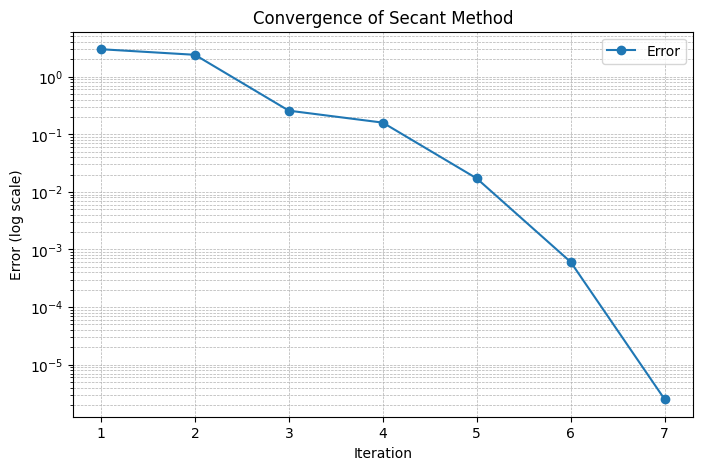

In [120]:
plt.figure(figsize=(8, 5))
plt.plot(iterations, errors, marker='o', label='Error')
plt.yscale('log')
plt.xlabel('Iteration')
plt.ylabel('Error (log scale)')
plt.title('Convergence of Secant Method')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.legend()
plt.show()